# 04 - Training & Evaluation
Trains each model from notebook 03 on Train/Val, then compares them on the held-out Test set. Progress updates a single widget line in place instead of flooding notebook output.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd

from src.models import RidgeModel, XGBoostModel
from src.metrics import pearson_ic, spearman_ic, hit_rate
from src.progress import NotebookProgress, XGBProgressCallback

DATA_DIR = PROJECT_ROOT / 'data'
SPLIT_DIR = DATA_DIR / 'splits'

In [2]:
train = pd.read_parquet(SPLIT_DIR / 'train.parquet')
val = pd.read_parquet(SPLIT_DIR / 'val.parquet')
test = pd.read_parquet(SPLIT_DIR / 'test.parquet')

target_col = [c for c in train.columns if c.startswith('fwd_log_return')][0]
feature_cols = [c for c in train.columns if c != target_col]

X_train, y_train = train[feature_cols], train[target_col]
X_val, y_val = val[feature_cols], val[target_col]
X_test, y_test = test[feature_cols], test[target_col]
X_train.shape, X_val.shape, X_test.shape

((3237, 12), (427, 12), (891, 12))

## Re-declare the models to train
(Mirror of notebook 03's `MODELS` dict - change the loss/hyperparameters here too if you're iterating quickly without re-running 03.)

In [3]:
XGB_LOSS = 'huber'  # 'squared' | 'mae' | 'huber'

MODELS = {
    'ridge': RidgeModel(alpha=1.0),
    'xgboost': XGBoostModel(loss=XGB_LOSS, n_estimators=500, max_depth=4,
                            learning_rate=0.05, subsample=0.7, colsample_bytree=0.7,
                            early_stopping_rounds=30),
}

## Train
Ridge fits instantly (closed-form). XGBoost shows a live in-place progress bar instead of one printed line per boosting round.

In [4]:
fitted = {}

for key, model in MODELS.items():
    print(f'Training {model.name} ...')
    if isinstance(model, XGBoostModel):
        progress = NotebookProgress(total=model._model.n_estimators, description=key)
        callback = XGBProgressCallback(progress, metric_name=XGB_LOSS if XGB_LOSS != 'squared' else 'rmse')
        model.fit(X_train, y_train, X_val, y_val, callbacks=[callback])
        progress.close(f'best_iteration={model.best_iteration}')
    else:
        model.fit(X_train, y_train, X_val, y_val)
    fitted[key] = model

print('Done.')

Training Ridge(alpha=1.0) ...
Training XGBoost(loss=huber) ...


Done.


## Evaluate on the held-out Test set

In [5]:
rows = []
for key, model in fitted.items():
    pred = model.predict(X_test)
    rows.append({
        'model': model.name,
        'pearson_ic': pearson_ic(y_test.values, pred),
        'spearman_ic': spearman_ic(y_test.values, pred),
        'hit_rate': hit_rate(y_test.values, pred),
    })

results = pd.DataFrame(rows).set_index('model')
results

,pearson_ic,spearman_ic,hit_rate
model,,,
Ridge(alpha=1.0),0.041645,-0.040118,0.471380
XGBoost(loss=huber),0.060334,0.106790,0.544332


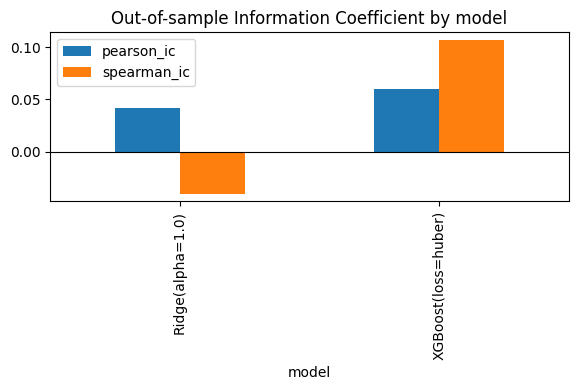

In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4))
results[['pearson_ic', 'spearman_ic']].plot.bar(ax=ax)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Out-of-sample Information Coefficient by model')
plt.tight_layout()
plt.show()

## Persist trained models
Saved so notebook 05 (visualizations) can load them without retraining.

In [7]:
import joblib

MODEL_DIR = DATA_DIR / 'models'
MODEL_DIR.mkdir(exist_ok=True)

for key, model in fitted.items():
    joblib.dump(model, MODEL_DIR / f'{key}.joblib')

results.to_parquet(MODEL_DIR / 'results.parquet')
print(f'Saved {list(fitted.keys())} and results.parquet to {MODEL_DIR}')

Saved ['ridge', 'xgboost'] and results.parquet to /Users/user/Desktop/python/quant/CNN-agent/data/models
